In [75]:
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt

In [76]:
df = sb.load_dataset("titanic") # 타이타닉 생존자 정보

In [77]:
df.columns
# survived : 생존 여부. 1(생존), 0(사망)
# pclass : 객실 등급. 1, 2, 3
# sex : 성별
# age : 나이
# sibsp/parch : 함께 탄 형제, 배우자수 / 부모 자녀수
# fare : 운임
# embarked : 탑승항구. C,Q,S
# deck : 객실갑판

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='str')

In [78]:
# 결측치를 확인
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [79]:
# age는 중앙값으로 결측치를 채움
df["age"].median()

np.float64(28.0)

In [80]:
# age 결측치는 중앙값으로 채움
age_df = df["age"].fillna(df["age"].median())
age_df.isna().sum()

np.int64(0)

In [81]:
# embarked 결측치는 embarked가 가장 많이 나온 값으로 채움
eb_df = df["embarked"].fillna(df["embarked"].mode()[0]) # embarked 속성의 값들 중 가장 많이 나온 값들 중 첫번째
et_df = df["embark_town"].fillna(df["embark_town"].mode()[0])

In [82]:
na_df = df.fillna({
    "age" : df["age"].median(),
    "embarked" : df["embarked"].mode()[0],
    "embark_town" : df["embark_town"].mode()[0]
})

In [84]:
# deak는 결측치가 대부분이어서 제거
na_df = df.drop("deck", axis=1) # na_df = na_df.drop(columns=["deck"])
na_df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive',
       'alone'],
      dtype='str')

In [86]:
# 전체 생존율을 확인
na_df["survived"].mean()

np.float64(0.3838383838383838)

In [92]:
# 성별 생존율
# na_df.groupby("컬럼")
na_df.groupby("sex")["survived"].mean()

# 객실 등급별 생존율
na_df.groupby("pclass")["survived"].mean()

pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64

In [94]:
# 성별, 등급별 생존율
pd.pivot_table(na_df, values="survived", index="sex", columns="pclass", aggfunc="mean")

pclass,1,2,3
sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


In [97]:
# 나이대별 생존율
# 나이대 컬럼을 추가

na_df["age_group"] = pd.cut(na_df["age"], 

                            bins=[0, 10, 20, 30, 40, 50, 60, 100], 
                            labels=["10세 미만", "10대", "20대", "30대", "40대", "50대", "60대 이상"])

In [98]:
na_df.head(5)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,age_group
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,20대
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,30대
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,20대
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,30대
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,30대


In [99]:
na_df.groupby("age_group")["survived"].mean()

age_group
10세 미만    0.593750
10대       0.382609
20대       0.365217
30대       0.445161
40대       0.383721
50대       0.404762
60대 이상    0.227273
Name: survived, dtype: float64

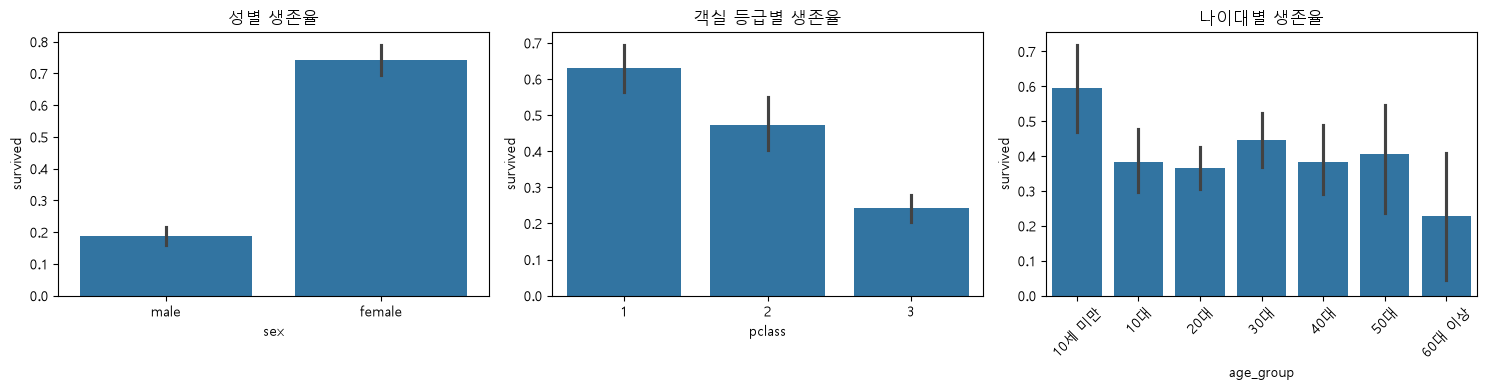

In [100]:
plt.rcParams["font.family"] = "Malgun Gothic"   # Mac은 "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sb.barplot(data=na_df, x="sex", y="survived", ax=axes[0])
axes[0].set_title("성별 생존율")

sb.barplot(data=na_df, x="pclass", y="survived", ax=axes[1])
axes[1].set_title("객실 등급별 생존율")

sb.barplot(data=na_df, x="age_group", y="survived", ax=axes[2])
axes[2].set_title("나이대별 생존율")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()